## **Shallow water equations**

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:

#IMPORT LIBRARIES

import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sys
import cmcrameri.cm as cmc
import pandas as pd

from the_well.data import WellDataset
from the_well.utils.download import well_download

# Add parent directory to path to access src module
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent.parent))
print("Current working directory:", Path.cwd())
print("Parent directory added to path:", Path.cwd().parent.parent)

# Importing modules from src
from src.datamanager import ROMDataManager, DataManager
from src.engine import SHREDEngine
from src.train import fit, evaluate
from src.mSHRED.mSHRED import mSHRED
from src.utils import plot_training_curves, evaluate_model

# get device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

Current working directory: /home/matteo/Documents/Masked-SHRED/Notebooks/SWE
Parent directory added to path: /home/matteo/Documents/Masked-SHRED


## Data Load

In [3]:
# ONLY RUN THIS ONCE TO DOWNLOAD THE DATASET
#well_download(base_path="", dataset="planetswe", split="train", first_only=True)

# LOAD THE DATASET
data_folder = "datasets"
dataset = WellDataset(
    well_base_path = data_folder,
    well_dataset_name = "planetswe",
    well_split_name = "train",
    n_steps_input = 1008,
    n_steps_output = 0,
    use_normalization = False,
)
#I've downloaded 0 and 1, you can change this to load the other ones
dataset = dataset[0] 

# BUILD SNAPSHOTS MATRICES

theta = dataset["space_grid"][:,:,0]    # theta: colatitude angle (radians) at each grid point, shape (Lx, Ly)
phi = dataset["space_grid"][:,:,1]      # phi: longitude angle (radians) at each grid point, shape (Lx, Ly)

print("theta shape:\t", theta.shape)
print("phi shape:\t", phi.shape)

ntimes, Lx, Ly, _ = dataset['input_fields'].shape   # ntimes: number of time steps, Lx: number of grid points in x (colatitude), Ly: number of grid points in y (longitude)
nheight = nvelocity = Lx * Ly                       # total number of spatial grid points (flattened)

print("ntimes:\t\t", ntimes)    
print("Lx:\t\t", Lx)            
print("Ly:\t\t", Ly)            
print("nheight:\t", nheight)
print("nvelocity:\t", nvelocity)

H = dataset["input_fields"][:,:,:,0].reshape(ntimes, nheight)           # H: snapshot matrix of height deviation h(x,t), shape (ntimes, nheight)
Utheta = dataset["input_fields"][:,:,:,1].reshape(ntimes, nvelocity)    # Utheta: snapshot matrix of velocity component along colatitude, shape (ntimes, nvelocity)
Uphi = dataset["input_fields"][:,:,:,2].reshape(ntimes, nvelocity)      # Uphi: snapshot matrix of velocity component along longitude, shape (ntimes, nvelocity)

print("H shape:\t", H.shape)
print("Utheta shape:\t", Utheta.shape)
print("Uphi shape:\t", Uphi.shape)

# DELETE DATASET TO FREE UP MEMORY

del dataset

theta shape:	 torch.Size([256, 512])
phi shape:	 torch.Size([256, 512])
ntimes:		 1008
Lx:		 256
Ly:		 512
nheight:	 131072
nvelocity:	 131072
H shape:	 torch.Size([1008, 131072])
Utheta shape:	 torch.Size([1008, 131072])
Uphi shape:	 torch.Size([1008, 131072])


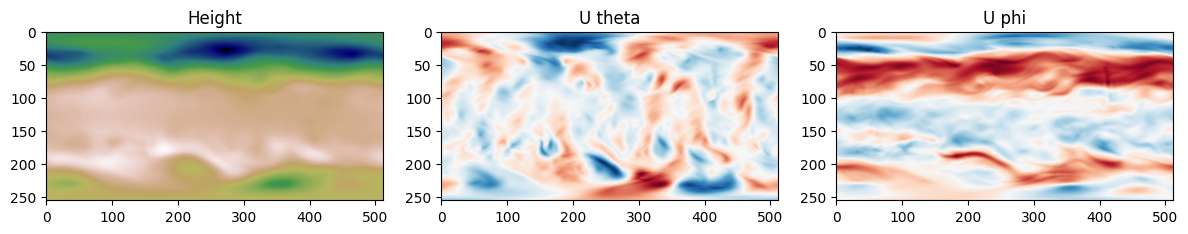

In [4]:
# Define a function to plot the state of the system at a given time step
def plot_state(u, cmap = "RdBu_r"):
    fig = plt.imshow(u.reshape(Lx, Ly), cmap = cmap)

plot_height = lambda u: plot_state(u, cmap = "gist_earth")
plot_velocity = lambda u: plot_state(u, cmap = "RdBu_r")

# Plot the state of the system at the first time step
plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
plot_height(H[0])
plt.title("Height")
plt.subplot(1, 3, 2)
plot_velocity(Utheta[0])
plt.title("U theta")
plt.subplot(1, 3, 3)        
plot_velocity(Uphi[0])
plt.title("U phi")
plt.tight_layout()
plt.show()

## SENSOR extraction

In [5]:
# EXTRACT SENSORS DATA 

# We randomly select 10 sensors on the grid and extract their time series data from the height field H. 
nsensors = 10
sensors_coordinates = np.vstack((np.random.choice(Lx, size = nsensors, replace = True), np.random.choice(Ly, size = nsensors, replace = True))).T
sensors_data = H.reshape(ntimes, Lx, Ly)[:,sensors_coordinates[:,0], sensors_coordinates[:,1]]
print("Sensors coordinates:\n", sensors_coordinates)
print("Sensors data shape:\t", sensors_data.shape)

# BROKEN SENSORS SIMULATION
# short broken : random Bernoulli drops
# long broken  : contiguous outage interval

short_broken = 4   # number of sensors with random drops
long_broken  = 4   # number of sensors with a contiguous outage

# Assign which sensors are broken (first short_broken sensors → random drops,
# next long_broken sensors → long outage)
idx_short_broken_s = np.arange(0, short_broken)
idx_long_broken_s  = np.arange(short_broken, short_broken + long_broken)

# Work on a float copy so NaN can be written
sensors_data = sensors_data.float()

# SHORT BROKEN: Bernoulli mask with probability p_short_broken
p_short_broken = 0.2
for local_idx in idx_short_broken_s:
    broken_mask = torch.rand(sensors_data[:, local_idx].shape) < p_short_broken
    print(f"Short broken sensor {local_idx} (coord {sensors_coordinates[local_idx]}): "
          f"{broken_mask.sum().item()} of {ntimes} steps masked")
    sensors_data[:, local_idx][broken_mask] = float('nan')

# LONG BROKEN: contiguous interval
for local_idx in idx_long_broken_s:
    t1, t2 = np.random.randint(0, ntimes, size=2)
    t_start, t_end = min(t1, t2), max(t1, t2)
    if t_end - t_start < 30:                          # ensure a minimum outage length
        t_end = min(t_start + 38, ntimes - 1)
    print(f"Long broken sensor  {local_idx} (coord {sensors_coordinates[local_idx]}): "
          f"steps {t_start} to {t_end} masked")
    sensors_data[t_start:t_end + 1, local_idx] = float('nan')

Sensors coordinates:
 [[  4  61]
 [ 37 288]
 [215  90]
 [ 88 348]
 [161 145]
 [101 501]
 [250 481]
 [ 99 196]
 [ 42  25]
 [  6 182]]
Sensors data shape:	 torch.Size([1008, 10])
Short broken sensor 0 (coord [ 4 61]): 236 of 1008 steps masked
Short broken sensor 1 (coord [ 37 288]): 188 of 1008 steps masked
Short broken sensor 2 (coord [215  90]): 191 of 1008 steps masked
Short broken sensor 3 (coord [ 88 348]): 222 of 1008 steps masked
Long broken sensor  4 (coord [161 145]): steps 357 to 866 masked
Long broken sensor  5 (coord [101 501]): steps 288 to 505 masked
Long broken sensor  6 (coord [250 481]): steps 164 to 653 masked
Long broken sensor  7 (coord [ 99 196]): steps 408 to 466 masked


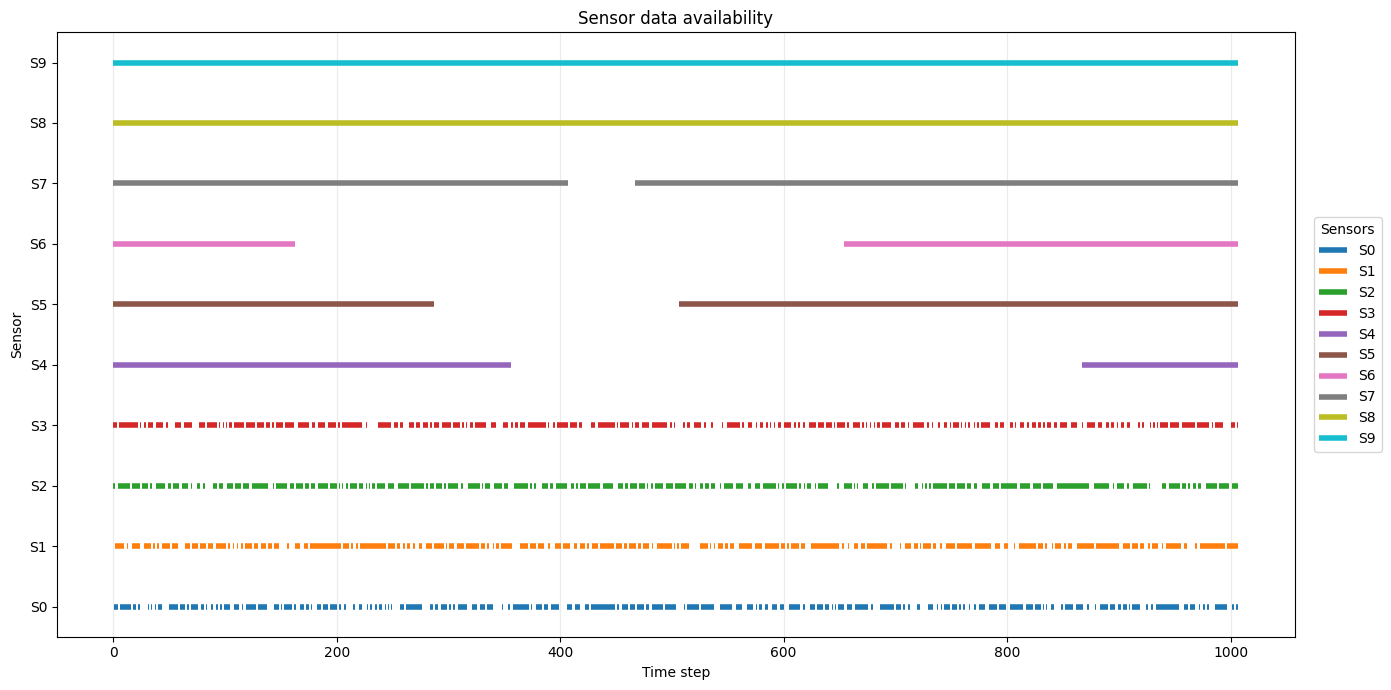

In [6]:
# PLOT DATA AVAILABILITY

def plot_data_availability(sensor_data, title_prefix, sensor_labels=None):
    """sensor_data: (ntimes, nsensors)"""
    availability = (~torch.isnan(sensor_data)).to(torch.float32).cpu().numpy()
    time          = np.arange(availability.shape[0])
    nsensors_plot = availability.shape[1]

    if sensor_labels is None:
        sensor_labels = np.arange(nsensors_plot)
    sensor_labels = np.asarray(sensor_labels)

    fig_height = max(3.0, 0.7 * nsensors_plot)
    _, ax = plt.subplots(1, 1, figsize=(14, fig_height))

    for sensor_idx in range(nsensors_plot):
        line = np.where(availability[:, sensor_idx] > 0.5, sensor_idx + 1.0, np.nan)
        ax.plot(time, line, linewidth=4, solid_capstyle="butt", label=f"S{sensor_labels[sensor_idx]}")

    ax.set_xlabel("Time step")
    ax.set_ylabel("Sensor")
    ax.set_yticks(np.arange(1, nsensors_plot + 1))
    ax.set_yticklabels([f"S{label}" for label in sensor_labels])
    ax.set_ylim(0.5, nsensors_plot + 0.5)
    ax.grid(True, axis="x", alpha=0.25)
    ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), title="Sensors")
    plt.title(title_prefix)
    plt.tight_layout()
    plt.show()

plot_data_availability(sensors_data, "Sensor data availability", sensor_labels=np.arange(nsensors))

## Check -> USE ROM AS IN SHRED ROM

In [7]:
np.random.seed(42)  # For reproducibility

print("Sensors data shape:\t", sensors_data.shape)
print("H shape:\t\t", H.shape)

H = H.reshape(16, -1, 131072)
sensors_data = sensors_data.reshape(16, -1, 10)

permutation = np.random.permutation(sensors_data.shape[0])
sensors_data = sensors_data[permutation]
H = H[permutation]

print("Sensors data shape:\t", sensors_data.shape)
print("H shape:\t\t", H.shape)  

del Utheta, Uphi

Sensors data shape:	 torch.Size([1008, 10])
H shape:		 torch.Size([1008, 131072])
Sensors data shape:	 torch.Size([16, 63, 10])
H shape:		 torch.Size([16, 63, 131072])


## Paper image

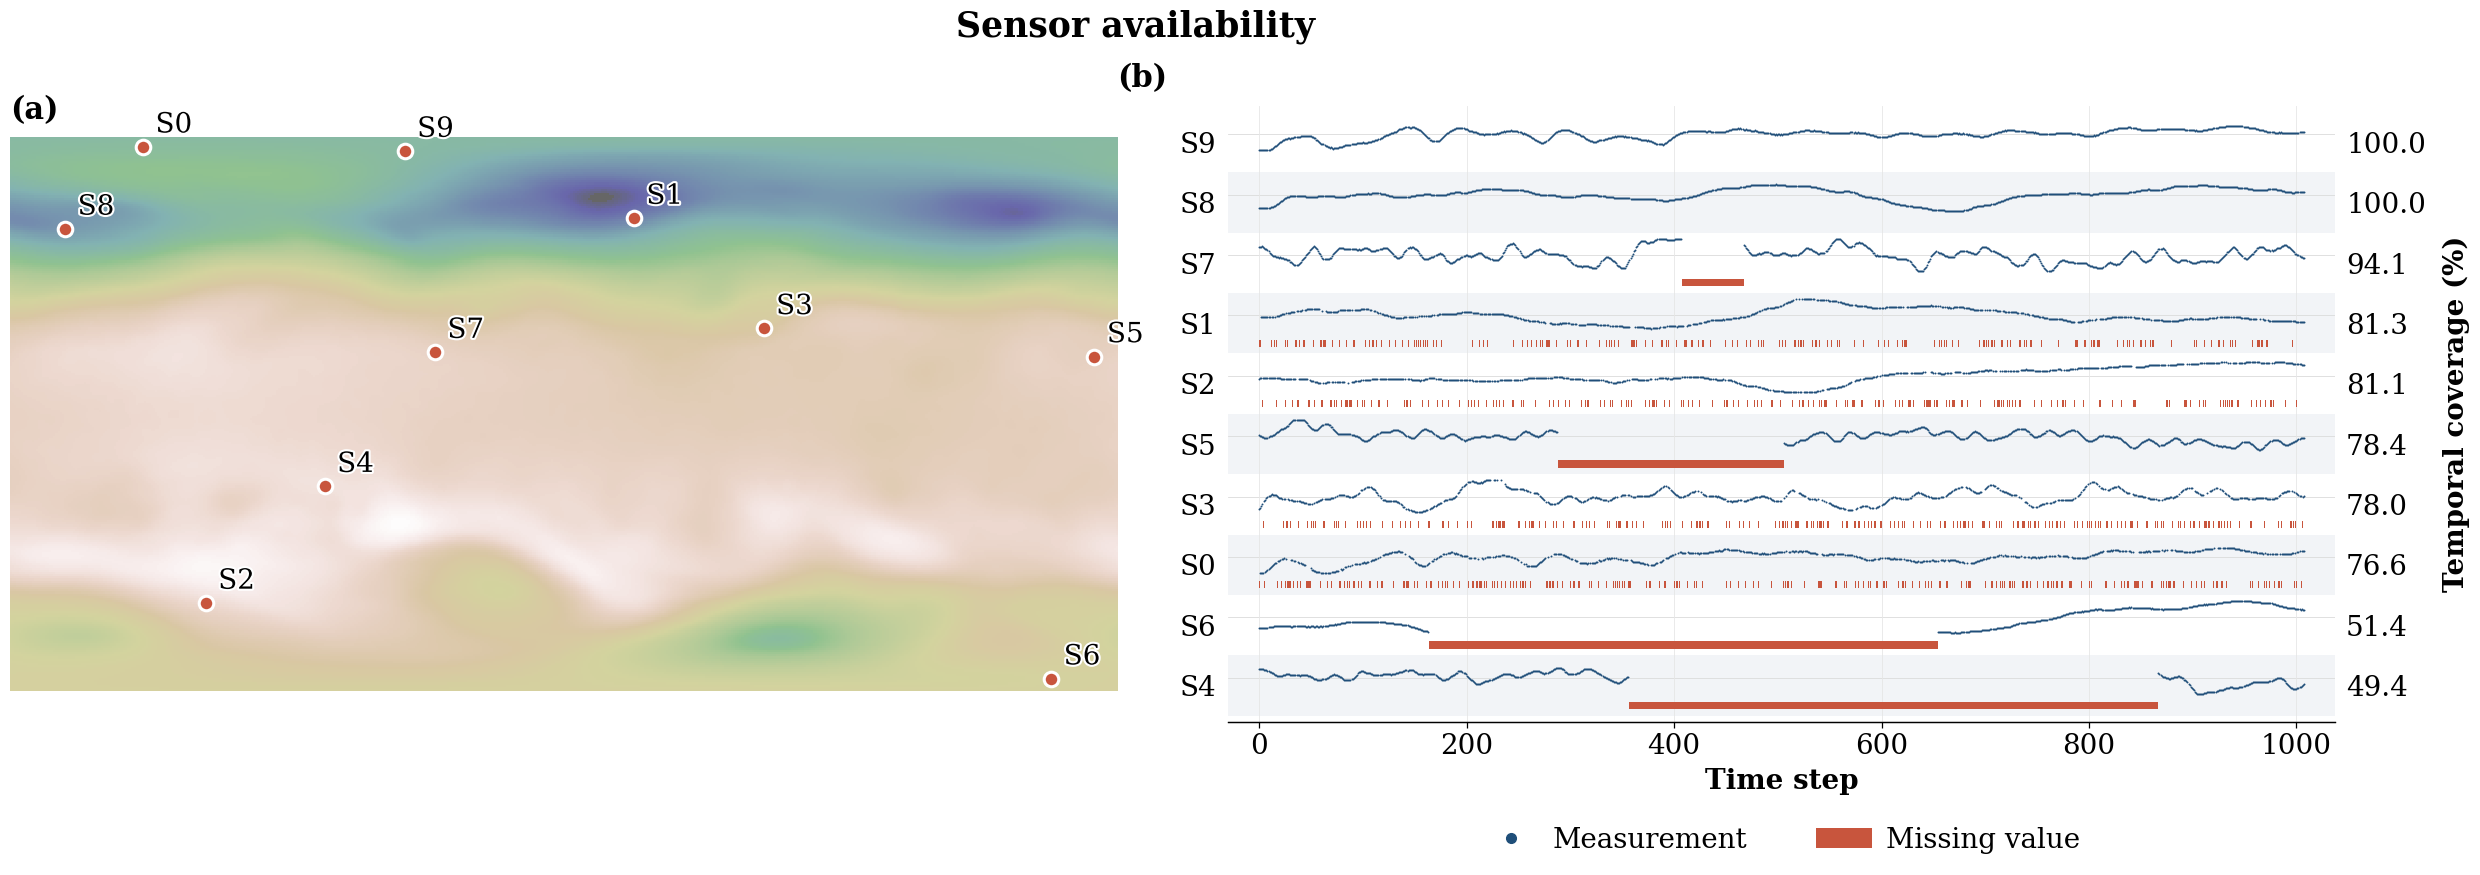

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.text import Text
from types import SimpleNamespace


# ------------------------------------------------------------------
# Style
# ------------------------------------------------------------------
PAPER_RC = {
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "axes.linewidth": 0.9,
    "xtick.direction": "out",
    "xtick.major.width": 0.9,
    "xtick.major.size": 4,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
}

C_DATA = "#1f4e79"      # valid measurements
C_NAN = "#c8553d"       # missing data
C_BAND = "#f2f4f7"      # alternating row band
C_MARK = "#c8553d"      # map sensor markers


# ------------------------------------------------------------------
# Data preparation (replaces get_wl_point_obs / ds / stations / msh)
# ------------------------------------------------------------------
def get_sensor_obs():
    """
    Build the objects needed by the plots from the notebook variables
    (sensors_data, sensors_coordinates, H).

    Cell 10 reshapes + shuffles sensors_data and H into (16, 63, ...) chunks.
    Here the shuffle is undone with `permutation`, so the time axis is the
    original one (0 ... ntimes-1).

    Returns
    -------
    obs_list : list of SimpleNamespace(name, values, x, y)
    H0       : (Lx, Ly) height field at the first time step (map background)
    ntimes   : number of time steps
    """
    sd = sensors_data.detach().cpu().numpy() if hasattr(sensors_data, "detach") else np.asarray(sensors_data)

    if sd.ndim == 3:                                  # cell 10 has been run
        inv = np.argsort(permutation)                 # inverse of the shuffle
        H0 = H[inv[0], 0]                             # first snapshot of the original series
        sd = sd[inv].reshape(-1, sd.shape[-1])        # back to (ntimes, nsensors)
    else:                                             # cell 10 NOT run
        H0 = H[0]

    H0 = H0.detach().cpu().numpy() if hasattr(H0, "detach") else np.asarray(H0)
    H0 = H0.reshape(Lx, Ly)

    obs_list = [
        SimpleNamespace(
            name=f"S{i}",
            values=sd[:, i],
            x=float(sensors_coordinates[i, 1]),       # column index (longitude direction)
            y=float(sensors_coordinates[i, 0]),       # row index (colatitude direction)
        )
        for i in range(sd.shape[1])
    ]
    return obs_list, H0, sd.shape[0]


# ------------------------------------------------------------------
# Sensor availability plot
# ------------------------------------------------------------------
def plot_station_availability(
    wllist,
    ntimes,
    ax=None,
    row_h=0.27,
    sig_offset=0.13,
    mask_offset=-0.33,
    mask_h=0.12,
    marker_size=1.4,
    c_data=C_DATA,
    c_nan=C_NAN,
    figsize=(30, 10),
    font_scale=1.0,
    time_pad_frac=0.03,
    xlim=None,
    show_title=True,
    panel_label=None,
    savepath=None,
    dpi=600,
):
    """
    Sensor availability against the time-step axis.
      - sensor stream: blue dots
      - missing data: red bars

    Returns: fig, ax, coverage_pct_by_name
    """
    fs = lambda x: x * font_scale

    time = np.arange(ntimes)
    coverage_pct_by_name = {}
    series_by_name = {}

    for obs in wllist:
        s = np.asarray(obs.values, dtype=float).ravel()
        series_by_name[obs.name] = s
        coverage_pct_by_name[obs.name] = 100.0 * np.isfinite(s).sum() / ntimes

    # Lowest coverage at bottom, highest at top
    wllist_sorted = sorted(wllist, key=lambda o: coverage_pct_by_name[o.name])
    n = len(wllist_sorted)

    if xlim is not None:
        t0, t1 = xlim
    else:
        pad = (ntimes - 1) * time_pad_frac
        t0, t1 = -pad, (ntimes - 1) + pad

    standalone = ax is None

    with plt.rc_context(PAPER_RC):
        if standalone:
            fig, ax = plt.subplots(figsize=figsize)
        else:
            fig = ax.figure

        for i, obs in enumerate(wllist_sorted):
            s = series_by_name[obs.name]
            mask = np.isfinite(s)

            y_sig = i + sig_offset
            y_mask = i + mask_offset

            if i % 2 == 0:
                ax.axhspan(i - 0.5, i + 0.5, color=C_BAND, zorder=-2, lw=0)

            ax.axhline(y_sig, color="0.86", lw=0.6, zorder=0)

            # Sensor stream
            if mask.any():
                vals = s[mask] - s[mask].mean()
                scale = np.percentile(np.abs(vals), 99)
                if not np.isfinite(scale) or scale <= 0:
                    scale = 1.0
                y = y_sig + np.clip(vals / scale, -1, 1) * row_h
                ax.plot(
                    time[mask], y,
                    linestyle="none", marker="o", ms=marker_size, mew=0,
                    color=c_data, zorder=2, rasterized=True,
                )

            # Missing data
            if (~mask).any():
                miss = (~mask).astype(int)
                edges = np.diff(np.concatenate([[0], miss, [0]]))
                starts = np.where(edges == 1)[0]
                ends = np.where(edges == -1)[0]

                min_w = (t1 - t0) * 0.0008
                widths = np.maximum(ends - starts, min_w)

                ax.broken_barh(
                    list(zip(starts, widths)),
                    (y_mask - mask_h / 2, mask_h),
                    facecolors=c_nan, edgecolors="none",
                    zorder=1, rasterized=True,
                )

        ax.set_ylim(-0.6, n - 0.4)
        ax.set_xlim(t0, t1)

        ax.tick_params(axis="x", labelsize=fs(20), pad=4)
        ax.set_xlabel("Time step", fontsize=fs(20), labelpad=6, fontweight="bold")

        # Left labels: sensor names
        ax.set_yticks(range(n))
        ax.set_yticklabels([o.name for o in wllist_sorted], fontsize=fs(20))
        ax.tick_params(axis="y", length=0, pad=8)

        # Right labels: temporal coverage
        ax2 = ax.twinx()
        ax2.set_ylim(ax.get_ylim())
        ax2.set_yticks(range(n))
        ax2.set_yticklabels(
            [f"{coverage_pct_by_name[o.name]:.1f}" for o in wllist_sorted],
            fontsize=fs(20),
        )
        ax2.tick_params(axis="y", length=0, pad=8)
        ax2.set_ylabel("Temporal coverage (%)", fontsize=fs(20), labelpad=12, fontweight="bold")

        ax.grid(axis="x", color="0.9", lw=0.6)
        ax.set_axisbelow(True)

        for a in (ax, ax2):
            for side in ("top", "left", "right"):
                a.spines[side].set_visible(False)

        if panel_label:
            ax.text(-0.30, 1.02, panel_label, transform=ax.transAxes,
                    fontsize=fs(20), fontweight="bold", va="bottom", ha="left")

        if standalone and show_title:
            ax.set_title("Sensor availability", fontsize=fs(20), pad=14, fontweight="bold")

        ax.legend(
            handles=[
                Line2D([0], [0], marker="o", ls="none", color=c_data, ms=7, label="Measurement"),
                Patch(facecolor=c_nan, edgecolor="none", label="Missing value"),
            ],
            loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2,
            frameon=False, fontsize=fs(20), handletextpad=0.5, columnspacing=2.5,
        )

        if standalone:
            fig.tight_layout()
            if savepath:
                fig.savefig(savepath, bbox_inches="tight", dpi=dpi)
            plt.show()

    return fig, ax, coverage_pct_by_name


# ------------------------------------------------------------------
# Map labels (no overlaps)
# ------------------------------------------------------------------
def _place_map_labels(ax, stations, fontsize=20, offset=(9, 6), pad=3.0, max_iter=500):
    """Sensor names on the map, pushed apart vertically; leader line only if moved."""
    fig = ax.figure
    pts = [(st.name, float(st.x), float(st.y)) for st in stations]

    for txt in list(ax.texts):
        txt.remove()

    halo = [pe.withStroke(linewidth=3.0, foreground="white")]
    k = fig.dpi / 72.0

    anns = [
        ax.annotate(
            name, xy=(x, y), xytext=offset, textcoords="offset points",
            fontsize=fontsize, ha="left", va="bottom", zorder=6, path_effects=halo,
            arrowprops=dict(arrowstyle="-", color="0.4", lw=0.7,
                            shrinkA=2, shrinkB=6, relpos=(0, 0.5)),
        )
        for name, x, y in pts
    ]

    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    n = len(anns)

    anchor = np.array([ax.transData.transform((x, y)) for _, x, y in pts])
    size = np.array([[b.width, b.height]
                     for b in (Text.get_window_extent(a, renderer) for a in anns)])

    off0 = np.tile(np.array(offset, float) * k, (n, 1))
    off = off0.copy()
    marker_r = 8.0 * k

    def box(i):
        x0, y0 = anchor[i] + off[i]
        return x0, y0, x0 + size[i, 0], y0 + size[i, 1]

    for _ in range(max_iter):
        moved = False
        for i in range(n):
            xi0, yi0, xi1, yi1 = box(i)

            # label-label overlap
            for j in range(i + 1, n):
                xj0, yj0, xj1, yj1 = box(j)
                ov_x = min(xi1, xj1) - max(xi0, xj0) + pad * k
                ov_y = min(yi1, yj1) - max(yi0, yj0) + pad * k
                if ov_x > 0 and ov_y > 0:
                    step = ov_y / 2 + 0.5
                    if yi0 + yi1 >= yj0 + yj1:
                        off[i, 1] += step
                        off[j, 1] -= step
                    else:
                        off[i, 1] -= step
                        off[j, 1] += step
                    moved = True
                    xi0, yi0, xi1, yi1 = box(i)

            # label-marker overlap
            for j in range(n):
                if j == i:
                    continue
                mx, my = anchor[j]
                ov_x = min(xi1, mx + marker_r) - max(xi0, mx - marker_r)
                ov_y = min(yi1, my + marker_r) - max(yi0, my - marker_r)
                if ov_x > 0 and ov_y > 0:
                    direction = 1.0 if (yi0 + yi1) / 2 >= my else -1.0
                    off[i, 1] += direction * (ov_y + 1.0)
                    moved = True
                    xi0, yi0, xi1, yi1 = box(i)

        if not moved:
            break

    for a, o, o_init in zip(anns, off, off0):
        a.xyann = (o[0] / k, o[1] / k)
        a.arrow_patch.set_visible(bool(np.hypot(*(o - o_init)) > 6 * k))


# ------------------------------------------------------------------
# Combined figure
# ------------------------------------------------------------------
def plot_overview_and_availability(
    wllist,
    H0,
    ntimes,
    figsize=(30, 9),
    font_scale=1.0,
    width_ratios=(0.33, 0.67),
    wspace=0.36,
    panel_labels=False,
    title="Sensor availability",
    savepath=None,
    dpi=600,
    **avail_kwargs,
):
    """
    Left : sensor locations over the height field at t = 0.
    Right: sensor availability timeline.

    Returns: fig, axs, coverage_pct_by_name
    """
    fs = lambda x: x * font_scale

    with plt.rc_context(PAPER_RC):
        fig = plt.figure(figsize=figsize)
        gs = fig.add_gridspec(1, 2, width_ratios=width_ratios, wspace=wspace)
        axs = [fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1])]

        # LEFT: spatial map (grid indices; row = colatitude, col = longitude)
        axs[0].imshow(H0, cmap="gist_earth", aspect="equal", alpha=0.6, interpolation="nearest")
        axs[0].scatter(
            [o.x for o in wllist], [o.y for o in wllist],
            s=fs(110), c=C_MARK, edgecolors="white", linewidths=2.2, zorder=5,
        )
        axs[0].set_xlim(-0.5, H0.shape[1] - 0.5)
        axs[0].set_ylim(H0.shape[0] - 0.5, -0.5)
        axs[0].set_axis_off()

        # RIGHT: availability
        _, _, cov = plot_station_availability(
            wllist, ntimes, ax=axs[1], font_scale=font_scale, **avail_kwargs
        )
        axs[1].set_title("")

        # Map labels
        _place_map_labels(axs[0], wllist, fontsize=fs(20))

        if panel_labels:
            axs[0].text(0.0, 1.02, "(a)", transform=axs[0].transAxes,
                        fontsize=fs(22), fontweight="bold", va="bottom", ha="left")
            axs[1].text(-0.10, 1.02, "(b)", transform=axs[1].transAxes,
                        fontsize=fs(22), fontweight="bold", va="bottom", ha="left")

        if title:
            fig.suptitle(title, fontsize=fs(25), fontweight="bold", x=0.5, y=1.0)

        if savepath:
            fig.savefig(savepath, bbox_inches="tight", dpi=dpi, facecolor="white")

        plt.show()

    return fig, axs, cov


# ==================================================================
# RUN
# ==================================================================
wllist, H0, ntimes_plot = get_sensor_obs()

fig, axs, cov = plot_overview_and_availability(
    wllist, H0, ntimes_plot,
    figsize=(30, 8),
    font_scale=1.0,
    width_ratios=(0.5, 0.5),
    wspace=0.1,
    panel_labels=True,
    title="Sensor availability",
    savepath="SWE_availability.png",
    dpi=300,   # 600 also works, just slower
)

